# День 5. Error analysis

Разбираю ошибки лучшей модели из дня 4 на том же test.

In [1]:
import sys
sys.path.insert(0, "../src")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from finnews_sentiment.features.preprocess import LABEL_NAMES

bundle = joblib.load("../models/best.joblib")
model = bundle["model"]
print(bundle["meta"])

{'model': 'word+char tfidf + logreg balanced, C=3', 'test_macro_f1': 0.7631, 'test_accuracy': 0.8262, 'improvement_%': 12.1}


Тот же сплит, что в днях 3-4, но делю весь датафрейм, чтобы рядом с ошибками были исходные тексты

In [2]:
df = pd.read_csv("data/financial_clean.csv").dropna(subset=["text_clean"])
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])
test_df = test_df.copy()

test_df["pred"] = model.predict(test_df["text_clean"])
test_df["pred_name"] = test_df["pred"].map(LABEL_NAMES)
test_df["confidence"] = model.predict_proba(test_df["text_clean"]).max(axis=1)

errors = test_df[test_df["pred"] != test_df["label"]]
print("ошибок:", len(errors), "из", len(test_df), f"({len(errors) / len(test_df):.1%})")

ошибок: 167 из 961 (17.4%)


In [3]:
names = list(LABEL_NAMES.values())
print(classification_report(test_df["label"], test_df["pred"], target_names=names))

              precision    recall  f1-score   support

    negative       0.62      0.62      0.62        69
     neutral       0.87      0.89      0.88       522
    positive       0.80      0.77      0.79       370

    accuracy                           0.83       961
   macro avg       0.76      0.76      0.76       961
weighted avg       0.83      0.83      0.83       961



### Confusion matrix

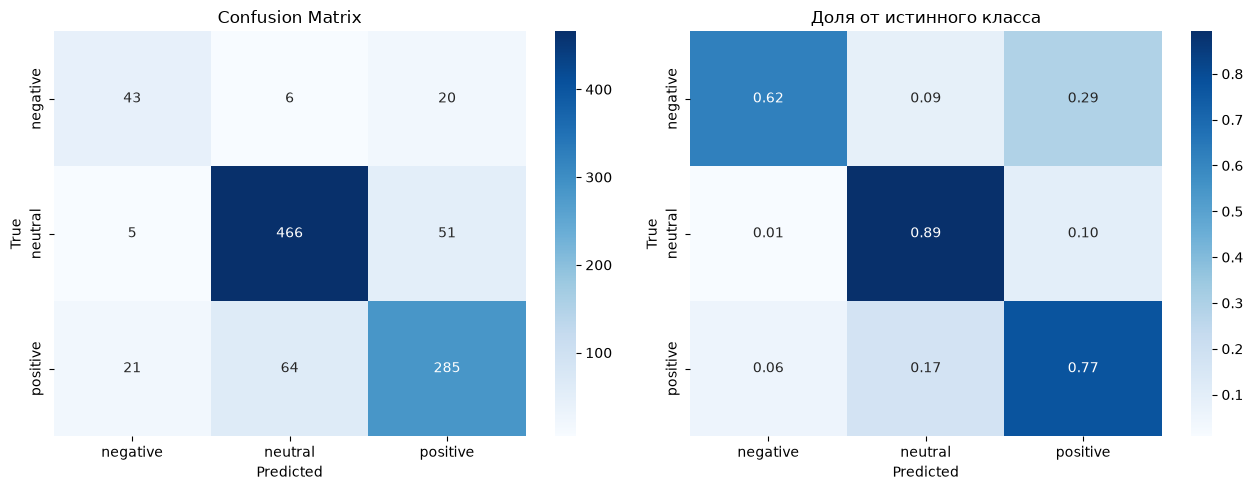

In [4]:
cm = confusion_matrix(test_df["label"], test_df["pred"])
cm_norm = confusion_matrix(test_df["label"], test_df["pred"], normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=axes[0])
axes[0].set_title("Confusion Matrix")
axes[0].set_ylabel("True")
axes[0].set_xlabel("Predicted")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names, ax=axes[1])
axes[1].set_title("Доля от истинного класса")
axes[1].set_ylabel("True")
axes[1].set_xlabel("Predicted")

plt.tight_layout()
plt.savefig("../reports/confusion_matrix.png", bbox_inches="tight")
plt.show()

### Какие классы путаются чаще всего

In [5]:
pairs = errors.groupby(["sentiment", "pred_name"]).size().sort_values(ascending=False)
pairs

sentiment  pred_name
positive   neutral      64
neutral    positive     51
positive   negative     21
negative   positive     20
           neutral       6
neutral    negative      5
dtype: int64

### Примеры ошибок для каждой пары

In [6]:
for (true_name, pred_name) in pairs.index:
    print(f"===== правда: {true_name} -> модель: {pred_name} =====")
    sample = errors[(errors["sentiment"] == true_name) & (errors["pred_name"] == pred_name)].head(4)
    for t in sample["text"]:
        print("-", t[:250])
    print()

===== правда: positive -> модель: neutral =====
- Nevertheless , Fitch notes that the business fundamentals of the three banks currently remain sound .
- Elisa said mobile subscriptions grew 7 percent during 2007 , mainly because of customers adopting so-called third generation mobile technology .
- Basware Corporation stock exchange release August 31 , 2010 at 16:25 Basware signed a large deal with an international industrial group Basware will deliver Invoice Automation solution and Connectivity Services to an international industrial group .
- Finnish energy company Fortum Oyj said on November 13 , 2007 it was granted an environmental permit to build a biofuel-fired combined heat and power CHP plant in Vartan harbor in eastern Stockholm .

===== правда: neutral -> модель: positive =====
- Sales were down 14 per cent in Finland and up 27 per cent abroad where sales were lifted by the strong growth in sales in Russia and Lithuania .
- To see a slide show of all the newest product rele

### Самые уверенные ошибки
Модель была уверена и ошиблась - часто здесь спорная разметка

In [7]:
for _, row in errors.sort_values("confidence", ascending=False).head(8).iterrows():
    print(f"[{row['sentiment']} -> {row['pred_name']}, уверенность {row['confidence']:.2f}]")
    print(row["text"][:250])
    print()

[positive -> neutral, уверенность 0.98]
The solutions will be used for upgrading the networks of a Russian MSO in 37 different cities in Russia .

[positive -> neutral, уверенность 0.97]
SINGAPORE ( ICIS ) -- ( 1 ) Kemira and Indian water infrastructure firm ( 2 ) IVRCL have agreed to form a join venture which includes a new inorganic coagulant manufacturing facility in Andhra Pradesh state , India , the Finnish water treatment chemi

[positive -> neutral, уверенность 0.94]
The company will also be compensated for acting as a reserve batch plant .

[positive -> neutral, уверенность 0.94]
SRV will raise its holding in the company so that by the summer of 2008 , it will have a majority .

[neutral -> positive, уверенность 0.94]
$ENDP Was looking for a long entry but today's price action wasn't appealing

[positive -> neutral, уверенность 0.93]
The negotiations were carried out in a constructive manner , and all parties tried to find a solution to the situation .

[neutral -> positive, ув

### Зависят ли ошибки от длины и от типа текста

In [8]:
test_df["is_error"] = test_df["pred"] != test_df["label"]
test_df["length_group"] = pd.qcut(test_df["word_count_clean"], 4, labels=["короткие", "ниже среднего", "выше среднего", "длинные"])
print(test_df.groupby("length_group", observed=True)["is_error"].mean().round(3))

# твиты с тикерами ($esi) против обычных новостных предложений
test_df["is_tweet"] = test_df["dollar_count"] > 0
print(test_df.groupby("is_tweet")["is_error"].agg(["mean", "count"]).round(3))

length_group
короткие         0.210
ниже среднего    0.179
выше среднего    0.176
длинные          0.129
Name: is_error, dtype: float64
           mean  count
is_tweet              
False     0.157    775
True      0.242    186


### На какие слова смотрит модель

In [9]:
vectorizer = model.named_steps["tfidf"]
clf = model.named_steps["clf"]
features = vectorizer.get_feature_names_out()

for i, name in LABEL_NAMES.items():
    top = np.argsort(clf.coef_[i])[-20:][::-1]
    words = [f.replace("word__", "") for f in features[top] if f.startswith("word__")]
    print(f"{name}: {', '.join(words)}")

negative: down, short, lower, fall, spy, price, drop, shell, share price, under, faces, put, weak, get, bearish, puts, bhp
neutral: is, the, and, be, of the, of, to the
positive: long, up, higher, rise, buy, positive, signed, in the, from eur, best, to, with, year, increase, grew, won, up from, awarded, strong


### Сохраняю анализ ошибок

In [10]:
with open("../reports/error_analysis.txt", "w") as f:
    f.write(f"Модель: {bundle['meta']['model']}\n")
    f.write(f"Ошибок: {len(errors)} из {len(test_df)} ({len(errors) / len(test_df):.1%})\n\n")
    f.write("Частые пары ошибок (правда -> модель):\n")
    f.write(pairs.to_string() + "\n\n")
    f.write("Примеры ошибок:\n")
    for (true_name, pred_name) in pairs.index:
        f.write(f"\n=== {true_name} -> {pred_name} ===\n")
        for t in errors[(errors["sentiment"] == true_name) & (errors["pred_name"] == pred_name)]["text"].head(5):
            f.write(f"- {t}\n")

errors[["text", "sentiment", "pred_name", "confidence"]].to_csv("../results/day05_errors.csv", index=False)
print(open("../reports/error_analysis.txt").read()[:1500])

Модель: word+char tfidf + logreg balanced, C=3
Ошибок: 167 из 961 (17.4%)

Частые пары ошибок (правда -> модель):
sentiment  pred_name
positive   neutral      64
neutral    positive     51
positive   negative     21
negative   positive     20
           neutral       6
neutral    negative      5

Примеры ошибок:

=== positive -> neutral ===
- Nevertheless , Fitch notes that the business fundamentals of the three banks currently remain sound .
- Elisa said mobile subscriptions grew 7 percent during 2007 , mainly because of customers adopting so-called third generation mobile technology .
- Basware Corporation stock exchange release August 31 , 2010 at 16:25 Basware signed a large deal with an international industrial group Basware will deliver Invoice Automation solution and Connectivity Services to an international industrial group .
- Finnish energy company Fortum Oyj said on November 13 , 2007 it was granted an environmental permit to build a biofuel-fired combined heat and power CHP

## Выводы

- ошибок 167 из 961 (17.4%)
- лучше всего модель находит neutral (recall 0.89), хуже всего negative (recall 0.62) - его меньше всего в данных (7%)
- главная путаница positive <-> neutral: 64 + 51 = 115 ошибок, две трети всех ошибок
- negative чаще путается с positive (29%), чем с neutral (9%) - путаница противоположных классов

failure cases:
1. отрицания и сарказм в твитах: "$FIO won't stay down", "does not want to go down" (positive -> negative),
   "the best scenario is this stock slowly falling" (сарказм, negative -> positive).
   модель на словах и n-граммах видит "down" или "best", но не понимает смысл фразы целиком
2. неявный позитив в формальных новостях: "subscriptions grew 7 percent", "signed a large deal",
   "fundamentals remain sound" - позитив выражен фактами, без эмоциональных слов, модель видит нейтральное изложение
3. смешанные новости: "sales were down 14% in Finland and up 27% abroad", "despite sales growth, Tesco cautions recovery to be bumpy"
4. спорная разметка: "net loss in 2009 was euro18.6 million" размечено как neutral,
   "solutions will be used for upgrading networks in 37 cities" размечено как positive -
   среди самых уверенных ошибок модели много таких случаев
5. тональность только в цифре: "$GPS comparable store sales -4%" - знак минуса модель не учитывает
6. мусор в данных: текст "..." - стоит отфильтровать тексты короче 2 слов

- длина: короткие тексты ошибаются чаще (21% против 13% у длинных) - мало слов-подсказок
- твиты с тикерами ошибаются чаще новостей (24% против 16%) - разговорный язык, сарказм, отрицания
- топ-слова классов: ...

что улучшать дальше:
- модель с контекстом (FinBERT, дообученный BERT) - понимает отрицания и смысл фразы целиком
- признак "отрицание" (not, won't, no + слово рядом) или биграммы с отрицаниями
- для цифр - отдельные признаки: знак изменения (+/-), слова up/down рядом с числом
- отфильтровать мусорные короткие тексты и перепроверить спорную разметку
